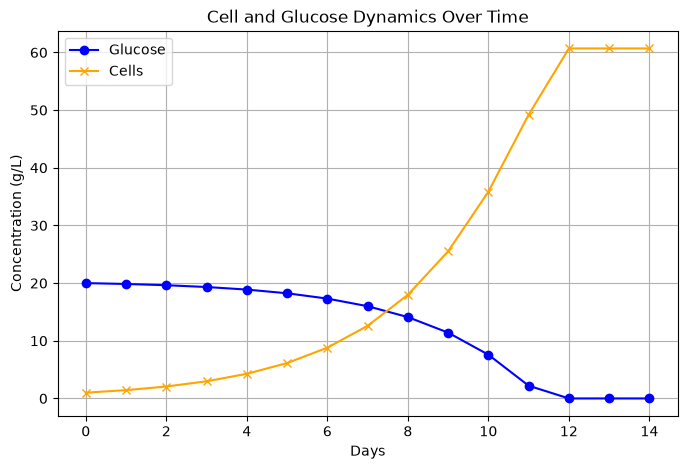

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
days = np.arange(0, 15, 1)
glucose = np.empty(len(days))
cells = np.empty(len(days))


# Initial conditions
glucose[0] = 20.0  # g/L
initial_cells = 1.0      # million cells/mL
cells[0] = initial_cells
glucose_consumption_rate = 0.15  # g/L per million cells per day
dt = 1.0  # time step in days

mu_max = 0.4 # g/L 
Ks = 2.0 # g/L

# Simple exponential growth model
for j in range(1, len(days)):
    mu = mu_max * glucose[j-1] / (Ks + glucose[j-1])  # Monod equation for growth rate
    cells[j] = cells[j-1] * np.exp(mu * dt)  # Cell growth
    glucose[j] = glucose[j-1] - (glucose_consumption_rate * cells[j-1] * dt)  # Glucose consumption
    if glucose[j] < 0:
        glucose[j] = 0  # Prevent negative glucose concentration

plt.figure(figsize=(8,5))
plt.plot(days, glucose, marker="o", label="Glucose", color='blue')
plt.plot(days, cells, marker="x", label="Cells", color='orange')
plt.title("Cell and Glucose Dynamics Over Time")
plt.xlabel("Days")
plt.ylabel("Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()

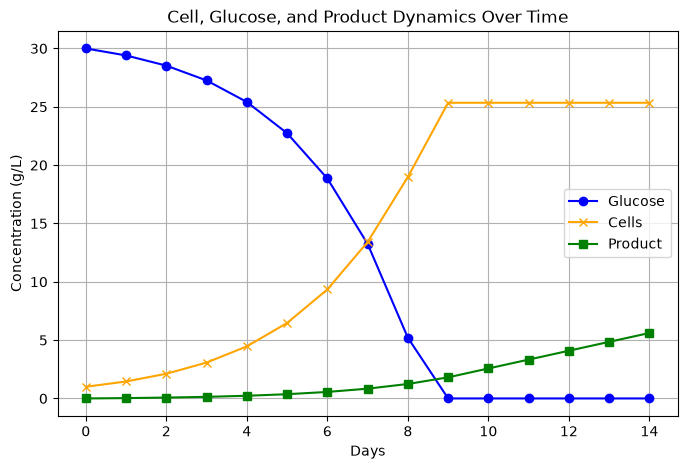

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
days = np.arange(0, 15, 1)
glucose = np.empty(len(days))
cells = np.empty(len(days))
product = np.empty(len(days))


# Initial conditions
glucose[0] = 30.0  # g/L
initial_cells = 1.0      # million cells/mL
cells[0] = initial_cells
product[0] = 0.0  # g/L

mu_max = 0.4 # 1/day 
Ks = 2.0 # g/L
qG = 600.0  # picograms / (cell . day)
dt = 1.0  # time step in days
qp = 30.0  # picograms / (cell . day)

# Simple exponential growth model
for i in range(1, len(days)):
    mu = mu_max * glucose[i-1] / (Ks + glucose[i-1])  # Monod equation for growth rate
    cells_per_L = cells[i-1] * 1e9  # million cells/mL to cells/L conversion factor
    glucose[i] = glucose[i-1] - (qG * cells_per_L * 1e-12 * dt)  # Glucose consumption
    product[i] = product[i-1] + (qp * cells_per_L * 1e-12 * dt)  # Product formation
    cells[i] = cells[i-1] * np.exp(mu * dt)  # Cell growth
    glucose[i] = max(glucose[i], 0)  # Prevent negative glucose concentration

plt.figure(figsize=(8,5))
plt.plot(days, glucose, marker="o", label="Glucose", color='blue')
plt.plot(days, cells, marker="x", label="Cells", color='orange')
plt.plot(days, product, marker="s", label="Product", color='green')
plt.title("Cell, Glucose, and Product Dynamics Over Time")
plt.xlabel("Days")
plt.ylabel("Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()

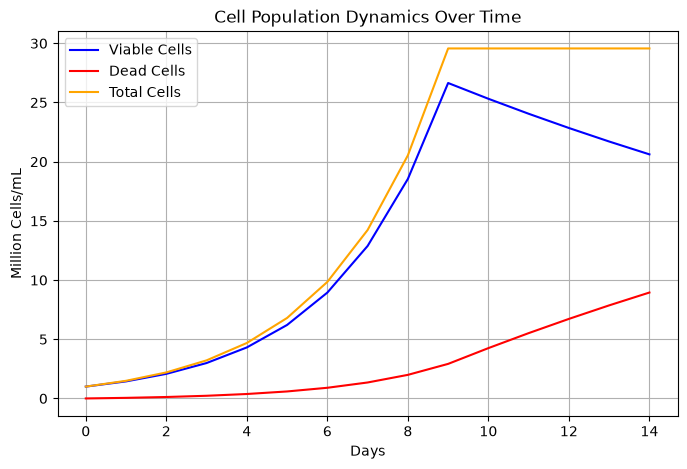

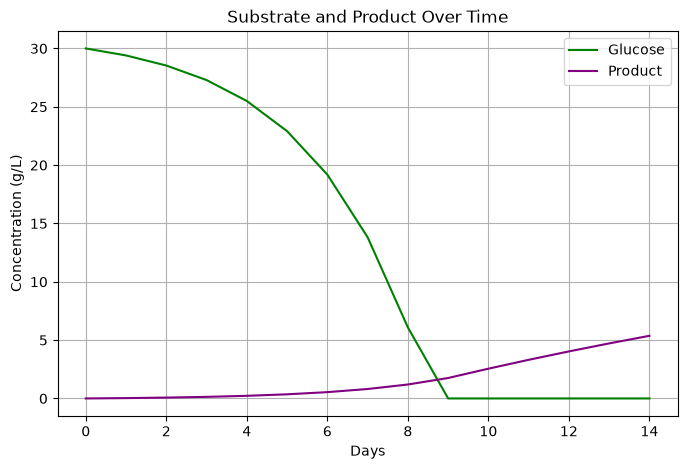

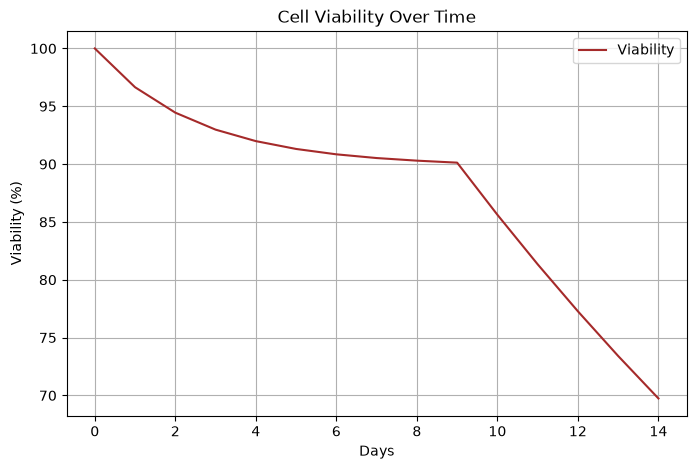

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
days = np.arange(0, 15, 1)
glucose = np.empty(len(days))
product = np.empty(len(days))
viable_cells = np.empty(len(days))
dead_cells = np.empty(len(days))


# Initial conditions
glucose[0] = 30.0  # g/L
initial_cells = 1.0      # million cells/mL
viable_cells[0] = initial_cells
dead_cells[0] = 0.0
product[0] = 0.0  # g/L

mu_max = 0.4 # 1/day 
Ks = 0.05 # g/L
qG = 600.0  # picograms / (cell . day)
dt = 1.0  # time step in days
qp = 30.0  # picograms / (cell . day)

#cell viability parameters
k_d = 0.05  # death rate constant (1/day)

#Cell Viability Model
for i in range(1, len(days)):
    mu = mu_max * glucose[i-1] / (Ks + glucose[i-1])  # Monod equation for growth rate
    cells_per_L = viable_cells[i-1] * 1e9  # million cells/mL to cells/L conversion factor
    glucose[i] = glucose[i-1] - (qG * cells_per_L * 1e-12 * dt)  # Glucose consumption
    glucose[i] = max(glucose[i], 0)  # Prevent negative glucose concentration
    product[i] = product[i-1] + (qp * cells_per_L * 1e-12 * dt)  # Product formation
    dead_today = k_d * viable_cells[i-1] * dt  # Number of cells that die today
    new_cells = viable_cells[i-1] * (np.exp(mu * dt) - 1)  # New viable cells produced
    viable_cells[i] = viable_cells[i-1] + new_cells - dead_today  # Viable cell growth and death
    viable_cells[i] = max(viable_cells[i], 0)
    dead_cells[i] = dead_cells[i-1] + dead_today  # Accumulation of dead cells

total_cells = viable_cells + dead_cells
viability = (viable_cells / total_cells) * 100

#Figure 1
plt.figure(figsize=(8,5))
plt.plot(days, viable_cells, label = "Viable Cells", color='blue')
plt.plot(days, dead_cells, label = "Dead Cells", color='red')
plt.plot(days, total_cells, label = "Total Cells", color='orange')
plt.title("Cell Population Dynamics Over Time")
plt.xlabel("Days")
plt.ylabel("Million Cells/mL")
plt.legend()
plt.grid()
plt.show()

#Figure 2
plt.figure(figsize=(8,5))
plt.plot(days, glucose, label = "Glucose", color='green')
plt.plot(days, product, label = "Product", color='purple')
plt.title("Substrate and Product Over Time")
plt.xlabel("Days")
plt.ylabel("Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()

#Figure 3
plt.figure(figsize=(8,5))
plt.plot(days, viability, label = "Viability", color='brown')
plt.title("Cell Viability Over Time")
plt.xlabel("Days")  
plt.ylabel("Viability (%)")
plt.legend()
plt.grid()  
plt.show()

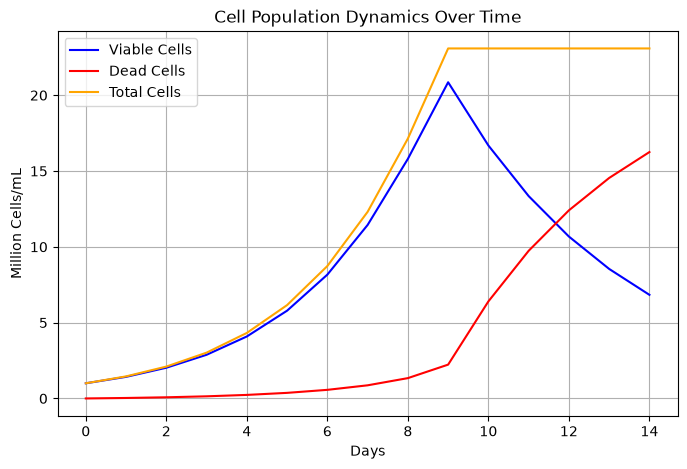

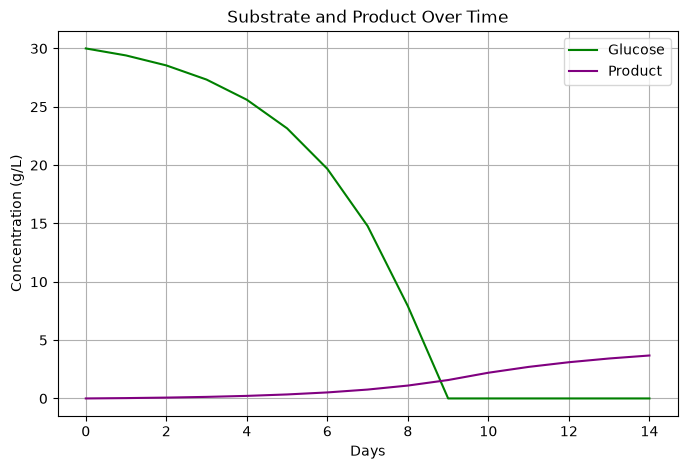

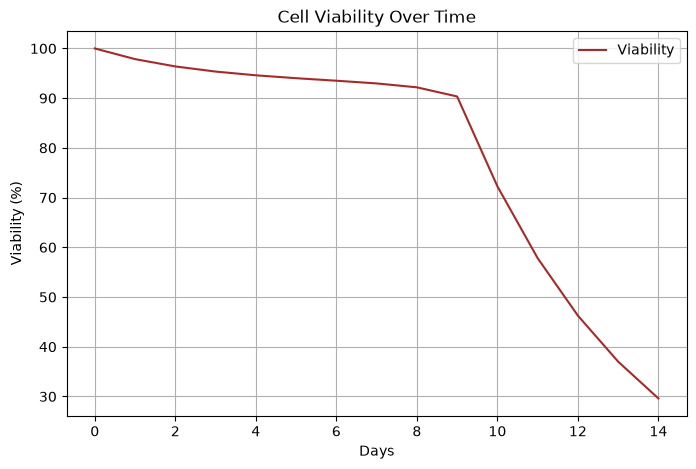

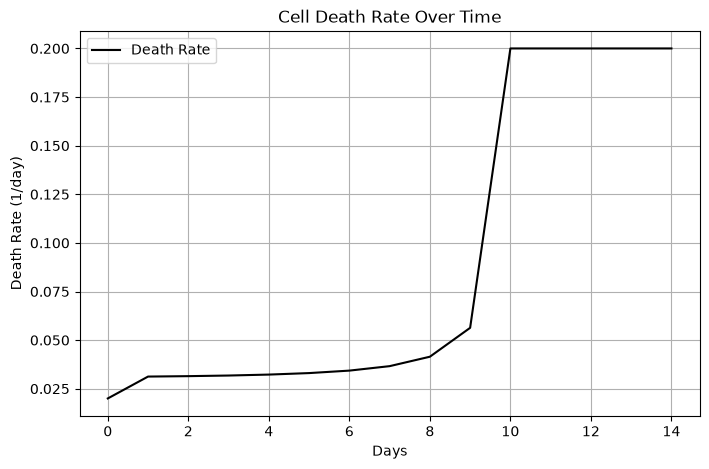

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
days = np.arange(0, 15, 1)
glucose = np.empty(len(days))
product = np.empty(len(days))
viable_cells = np.empty(len(days))
dead_cells = np.empty(len(days))
kd = np.empty(len(days))


# Initial conditions
glucose[0] = 30.0  # g/L
initial_cells = 1.0      # million cells/mL
viable_cells[0] = initial_cells
dead_cells[0] = 0.0
product[0] = 0.0  # g/L

mu_max = 0.4 # 1/day 
Ks = 2.0 # g/L
qG = 600.0  # picograms / (cell . day)
dt = 1.0  # time step in days
qp = 30.0  # picograms / (cell . day)

#cell viability parameters for dynamic death rate
kd_min = 0.02  # 1/day, death rate when glucose is high
kd_max = 0.20  # 1/day, death rate when glucose is depleted
kd[0] = kd_min # 1/day, initial death rate

#Cell Viability Model
for i in range(1, len(days)):
    mu = mu_max * glucose[i-1] / (Ks + glucose[i-1])  # Monod equation for growth rate
    health_factor = glucose[i-1] / (Ks + glucose[i-1])
    kd[i] = kd_min + (kd_max - kd_min) * (1 - health_factor)
    cells_per_L = viable_cells[i-1] * 1e9  # million cells/mL to cells/L conversion factor
    glucose[i] = glucose[i-1] - (qG * cells_per_L * 1e-12 * dt)  # Glucose consumption
    glucose[i] = np.maximum(glucose[i], 0)  # Prevent negative glucose concentration
    product[i] = product[i-1] + (qp * cells_per_L * 1e-12 * dt)  # Product formation
    dead_today = kd[i] * viable_cells[i-1] * dt  # Number of cells that die today
    new_cells = viable_cells[i-1] * (np.exp(mu * dt) - 1)  # New viable cells produced
    viable_cells[i] = viable_cells[i-1] + new_cells - dead_today  # Viable cell growth and death
    viable_cells[i] = np.maximum(viable_cells[i], 0)
    dead_cells[i] = dead_cells[i-1] + dead_today  # Accumulation of dead cells

total_cells = viable_cells + dead_cells
viability = (viable_cells / total_cells) * 100

#Figure 1
plt.figure(figsize=(8,5))
plt.plot(days, viable_cells, label = "Viable Cells", color='blue')
plt.plot(days, dead_cells, label = "Dead Cells", color='red')
plt.plot(days, total_cells, label = "Total Cells", color='orange')
plt.title("Cell Population Dynamics Over Time")
plt.xlabel("Days")
plt.ylabel("Million Cells/mL")
plt.legend()
plt.grid()
plt.show()

#Figure 2
plt.figure(figsize=(8,5))
plt.plot(days, glucose, label = "Glucose", color='green')
plt.plot(days, product, label = "Product", color='purple')
plt.title("Substrate and Product Over Time")
plt.xlabel("Days")
plt.ylabel("Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()

#Figure 3
plt.figure(figsize=(8,5))
plt.plot(days, viability, label = "Viability", color='brown')
plt.title("Cell Viability Over Time")
plt.xlabel("Days")  
plt.ylabel("Viability (%)")
plt.legend()
plt.grid()  
plt.show()

#Figure 4
plt.figure(figsize=(8,5))
plt.plot(days, kd, label = "Death Rate", color='black')
plt.title("Cell Death Rate Over Time")
plt.xlabel("Days")
plt.ylabel("Death Rate (1/day)")
plt.legend()
plt.grid()
plt.show()

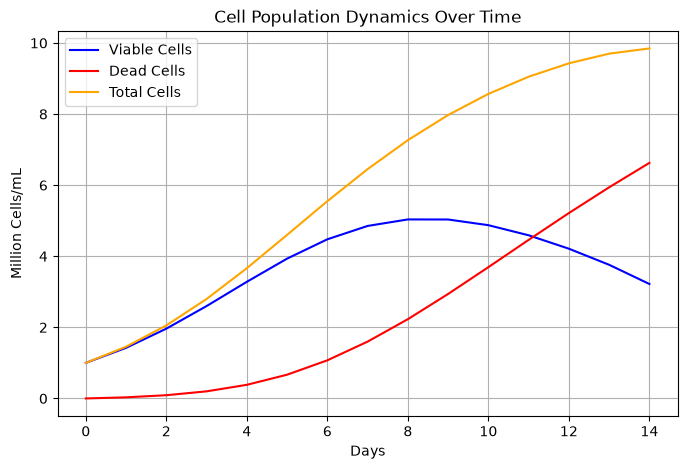

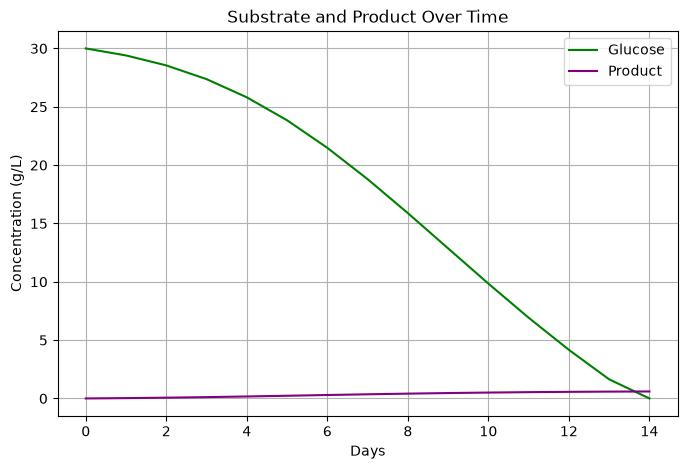

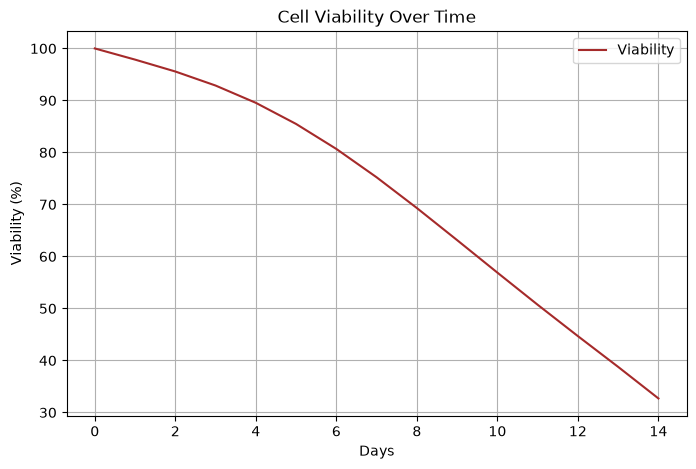

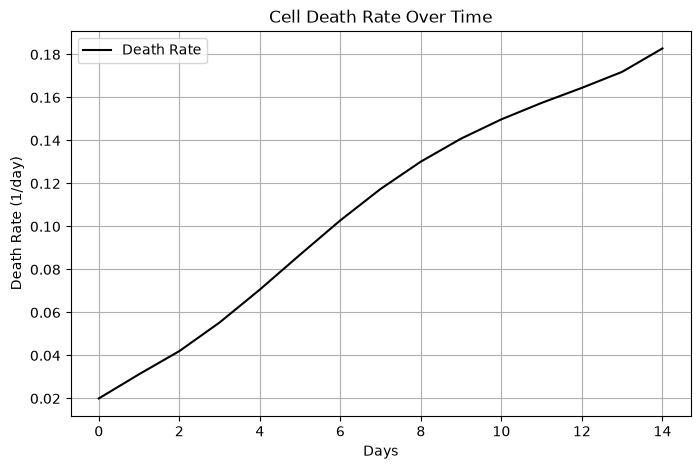

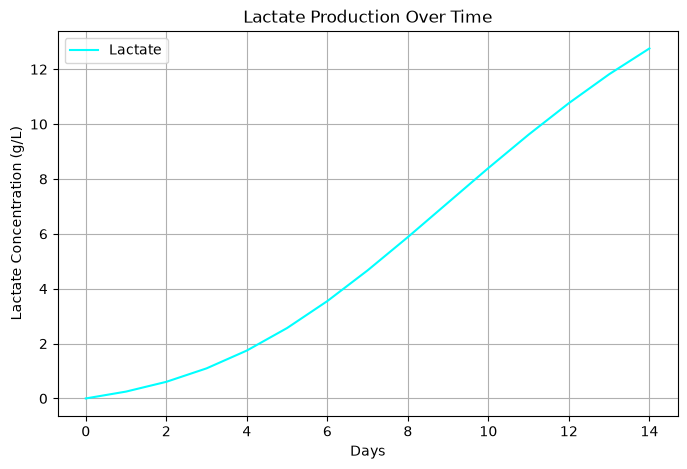

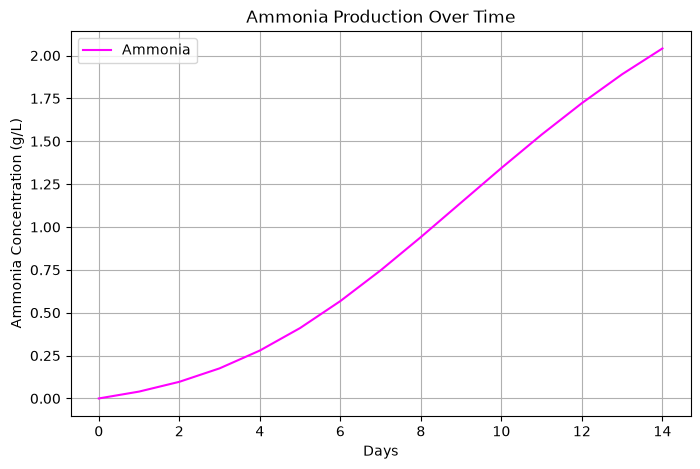

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
days = np.arange(0, 15, 1)
glucose = np.empty(len(days))
product = np.empty(len(days))
viable_cells = np.empty(len(days))
dead_cells = np.empty(len(days))
kd = np.empty(len(days))
lactate = np.empty(len(days))
ammonia = np.empty(len(days))


# Initial conditions
glucose[0] = 30.0  # g/L
initial_cells = 1.0      # million cells/mL
viable_cells[0] = initial_cells
dead_cells[0] = 0.0
product[0] = 0.0  # g/L
lactate[0] = 0.0  # g/L
ammonia[0] = 0.0  # g/L

mu_max = 0.4 # 1/day 
Ks = 2.0 # g/L
Kl = 4.0 # g/L, lactate inhibition constant
Ka = 2.0 # g/L, ammonia inhibition constant
qG = 600.0  # picograms / (cell . day)
dt = 1.0  # time step in days
qp = 30.0  # picograms / (cell . day)
qL = 250.0  # picograms / (cell . day), lactate production rate
qA = 40.0 # picograms / (cell . day), ammonia production rate

#cell viability parameters for dynamic death rate
kd_min = 0.02  # 1/day, death rate when glucose is high
kd_max = 0.20  # 1/day, death rate when glucose is depleted
kd[0] = kd_min # 1/day, initial death rate

#Cell Viability Model
for i in range(1, len(days)):
    #factors determining health
    glucose_factor = glucose[i-1] / (Ks + glucose[i-1])
    lactate_factor = Kl / (Kl + lactate[i-1])
    ammonia_factor = Ka / (Ka + ammonia[i-1])  # Ammonia inhibition factor
    health_factor = glucose_factor * lactate_factor * ammonia_factor
    dynamic_qp = qp * health_factor  # Adjust product formation rate based on health
    mu = mu_max * health_factor  # Monod equation for growth rate

    cells_per_L = viable_cells[i-1] * 1e9  # million cells/mL to cells/L conversion factor
    glucose[i] = glucose[i-1] - (qG * cells_per_L * 1e-12 * dt)  # Glucose consumption
    glucose[i] = np.maximum(glucose[i], 0)  # Prevent negative glucose concentration
    product[i] = product[i-1] + (dynamic_qp * cells_per_L * 1e-12 * dt)  # Product formation
    lactate[i] = lactate[i-1] + (qL * cells_per_L * 1e-12 * dt)  # Lactate production
    ammonia[i] = ammonia[i-1] + (qA * cells_per_L * 1e-12 * dt)  # Ammonia production
    kd[i] = kd_min + (kd_max - kd_min) * (1 - health_factor)
    dead_today = kd[i] * viable_cells[i-1] * dt  # Number of cells that die today
    new_cells = viable_cells[i-1] * (np.exp(mu * dt) - 1)  # New viable cells produced
    viable_cells[i] = viable_cells[i-1] + new_cells - dead_today  # Viable cell growth and death
    viable_cells[i] = np.maximum(viable_cells[i], 0)
    dead_cells[i] = dead_cells[i-1] + dead_today  # Accumulation of dead cells

total_cells = viable_cells + dead_cells
viability = (viable_cells / total_cells) * 100

#Figure 1
plt.figure(figsize=(8,5))
plt.plot(days, viable_cells, label = "Viable Cells", color='blue')
plt.plot(days, dead_cells, label = "Dead Cells", color='red')
plt.plot(days, total_cells, label = "Total Cells", color='orange')
plt.title("Cell Population Dynamics Over Time")
plt.xlabel("Days")
plt.ylabel("Million Cells/mL")
plt.legend()
plt.grid()
plt.show()

#Figure 2
plt.figure(figsize=(8,5))
plt.plot(days, glucose, label = "Glucose", color='green')
plt.plot(days, product, label = "Product", color='purple')
plt.title("Substrate and Product Over Time")
plt.xlabel("Days")
plt.ylabel("Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()

#Figure 3
plt.figure(figsize=(8,5))
plt.plot(days, viability, label = "Viability", color='brown')
plt.title("Cell Viability Over Time")
plt.xlabel("Days")  
plt.ylabel("Viability (%)")
plt.legend()
plt.grid()  
plt.show()

#Figure 4
plt.figure(figsize=(8,5))
plt.plot(days, kd, label = "Death Rate", color='black')
plt.title("Cell Death Rate Over Time")
plt.xlabel("Days")
plt.ylabel("Death Rate (1/day)")
plt.legend()
plt.grid()
plt.show()

#Figure 5
plt.figure(figsize=(8,5))
plt.plot(days, lactate, label = "Lactate", color='cyan')
plt.title("Lactate Production Over Time")
plt.xlabel("Days")
plt.ylabel("Lactate Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()

#Figure 6
plt.figure(figsize=(8,5))
plt.plot(days, ammonia, label = "Ammonia", color='magenta')
plt.title("Ammonia Production Over Time")
plt.xlabel("Days")
plt.ylabel("Ammonia Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()

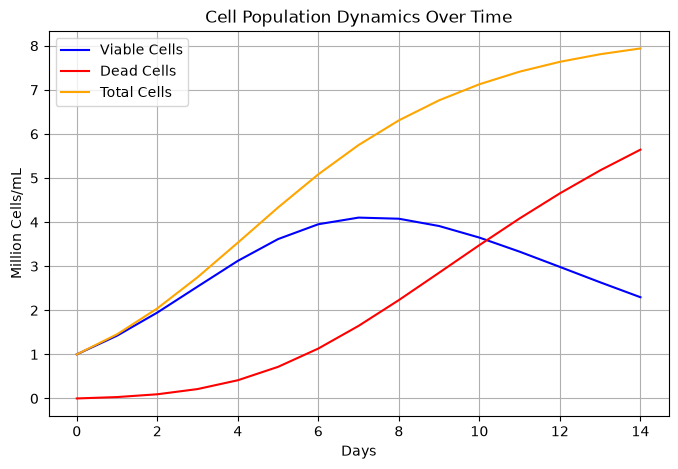

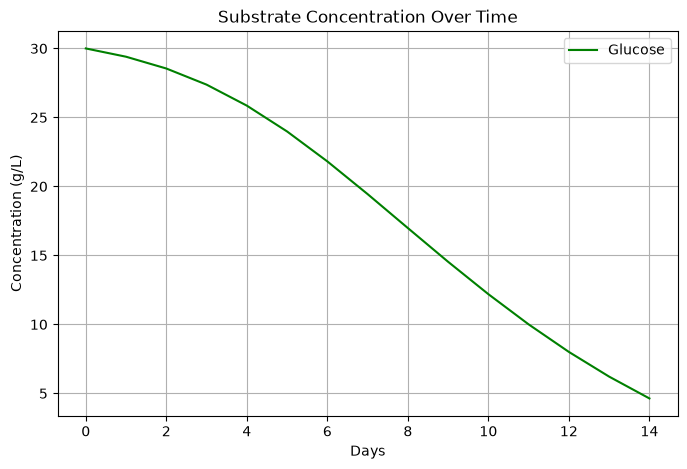

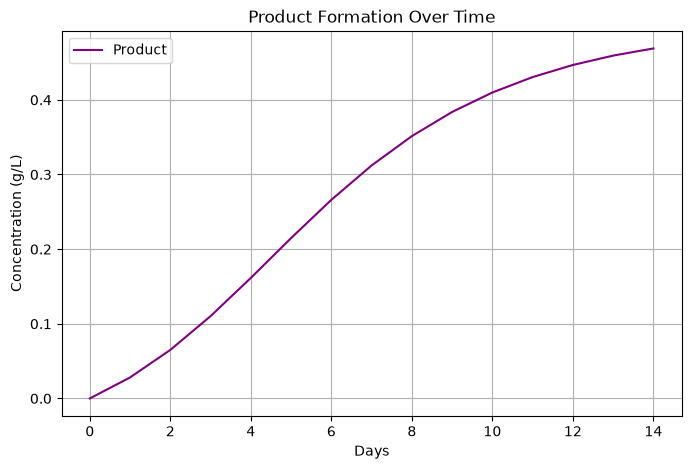

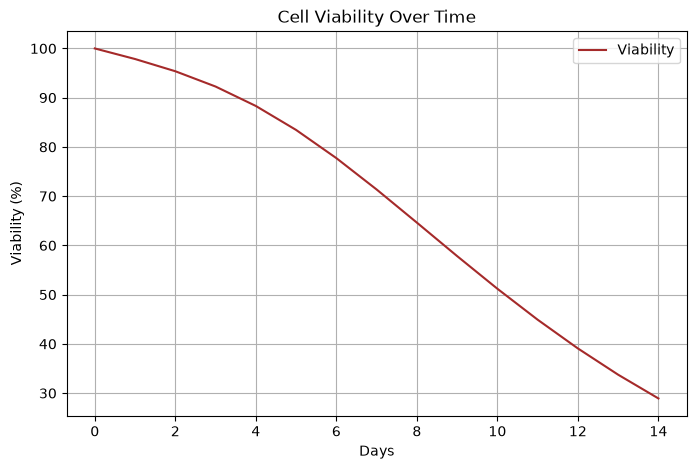

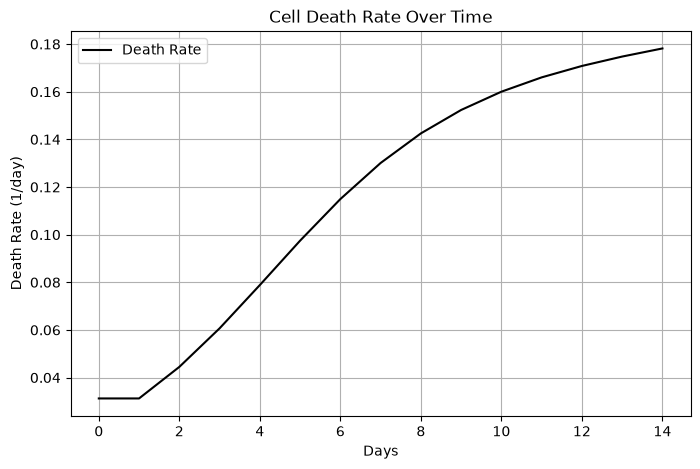

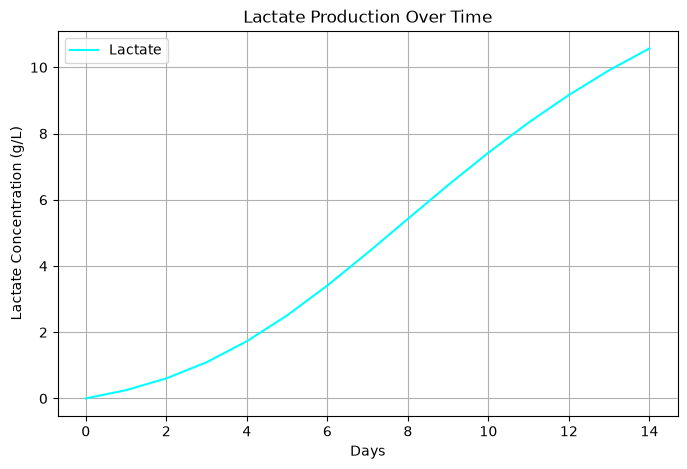

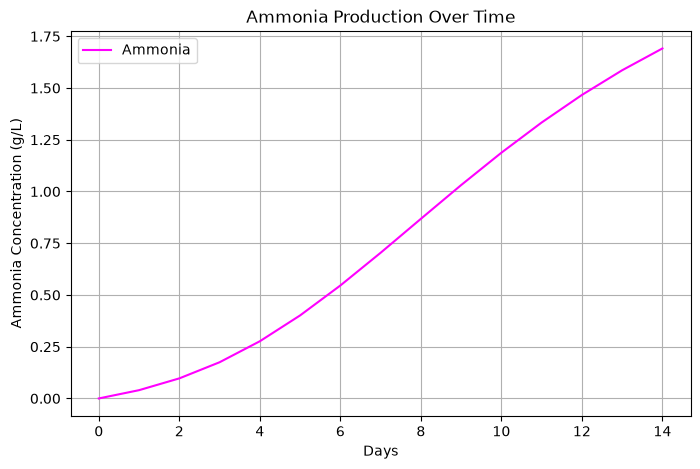

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# =====================================================
# MODEL FUNCTIONS
# =====================================================

def calculate_health(glucose, lactate, ammonia, Ks, Kl, Ka):
    glucose_factor = glucose / (Ks + glucose)
    lactate_factor = Kl / (Kl + lactate)
    ammonia_factor = Ka / (Ka + ammonia)

    health_factor = glucose_factor * lactate_factor * ammonia_factor

    return health_factor


def calculate_death_rate(health_factor, kd_min, kd_max):
    kd = kd_min + (kd_max - kd_min) * (1 - health_factor)

    return kd


def calculate_growth(viable_cells, mu, dt):
    new_cells = viable_cells * (np.exp(mu * dt) - 1)

    return new_cells


def update_metabolites(
    glucose_previous,
    product_previous,
    lactate_previous,
    ammonia_previous,
    viable_cells_previous,
    qG,
    qp,
    qL,
    qA,
    health_factor,
    dt,
):
    cells_per_L = viable_cells_previous * 1e9
    dynamic_qp = qp * health_factor

    glucose_demand = qG * cells_per_L * 1e-12 * dt

    actual_glucose_consumed = min(glucose_previous, glucose_demand)

    glucose_new = glucose_previous - actual_glucose_consumed
    product_new = product_previous + (dynamic_qp * cells_per_L * 1e-12 * dt)
    lactate_new = lactate_previous + (qL * cells_per_L * 1e-12 * dt)
    ammonia_new = ammonia_previous + (qA * cells_per_L * 1e-12 * dt)

    return glucose_new, product_new, lactate_new, ammonia_new


def update_cells(viable_cells_previous, dead_cells_previous, mu, kd, dt):
    new_cells = calculate_growth(viable_cells_previous, mu, dt)
    dead_today = kd * viable_cells_previous * dt
    dead_today = min(dead_today, viable_cells_previous + new_cells)  # Ensure dead cells do not exceed viable cells
    viable_cells_new = viable_cells_previous + new_cells - dead_today
    viable_cells_new = max(viable_cells_new, 0)

    dead_cells_new = dead_cells_previous + dead_today

    return viable_cells_new, dead_cells_new


# =====================================================
# PLOTTING FUNCTIONS
# =====================================================

def plot_cell_population(days, viable_cells, dead_cells, total_cells):
    plt.figure(figsize=(8, 5))
    plt.plot(days, viable_cells, label="Viable Cells", color="blue")
    plt.plot(days, dead_cells, label="Dead Cells", color="red")
    plt.plot(days, total_cells, label="Total Cells", color="orange")
    plt.title("Cell Population Dynamics Over Time")
    plt.xlabel("Days")
    plt.ylabel("Million Cells/mL")
    plt.legend()
    plt.grid()
    plt.show()


def plot_substrate(days, glucose):
    plt.figure(figsize=(8, 5))
    plt.plot(days, glucose, label="Glucose", color="green")
    plt.title("Substrate Concentration Over Time")
    plt.xlabel("Days")
    plt.ylabel("Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()

def plot_product(days, product):
    plt.figure(figsize=(8, 5))
    plt.plot(days, product, label="Product", color="purple")
    plt.title("Product Formation Over Time")
    plt.xlabel("Days")
    plt.ylabel("Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_viability(days, viability):
    plt.figure(figsize=(8, 5))
    plt.plot(days, viability, label="Viability", color="brown")
    plt.title("Cell Viability Over Time")
    plt.xlabel("Days")
    plt.ylabel("Viability (%)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_death_rate(days, kd):
    plt.figure(figsize=(8, 5))
    plt.plot(days, kd, label="Death Rate", color="black")
    plt.title("Cell Death Rate Over Time")
    plt.xlabel("Days")
    plt.ylabel("Death Rate (1/day)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_lactate(days, lactate):
    plt.figure(figsize=(8, 5))
    plt.plot(days, lactate, label="Lactate", color="cyan")
    plt.title("Lactate Production Over Time")
    plt.xlabel("Days")
    plt.ylabel("Lactate Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_ammonia(days, ammonia):
    plt.figure(figsize=(8, 5))
    plt.plot(days, ammonia, label="Ammonia", color="magenta")
    plt.title("Ammonia Production Over Time")
    plt.xlabel("Days")
    plt.ylabel("Ammonia Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_results(
    days,
    viable_cells,
    dead_cells,
    total_cells,
    glucose,
    product,
    viability,
    kd,
    lactate,
    ammonia,
):
    plot_cell_population(days, viable_cells, dead_cells, total_cells)
    plot_substrate(days, glucose)
    plot_product(days, product)
    plot_viability(days, viability)
    plot_death_rate(days, kd)
    plot_lactate(days, lactate)
    plot_ammonia(days, ammonia)


# =====================================================
# MAIN SIMULATION
# =====================================================

def main():

    # ----------------------------
    # Simulation settings
    # ----------------------------

    days = np.arange(0, 15)

    glucose = np.empty(len(days))
    product = np.empty(len(days))
    viable_cells = np.empty(len(days))
    dead_cells = np.empty(len(days))
    kd = np.empty(len(days))
    lactate = np.empty(len(days))
    ammonia = np.empty(len(days))

    # ----------------------------
    # Initial Conditions
    # ----------------------------

    glucose[0] = 30.0                   # g/L
    initial_cells = 1.0                 # million cells/mL
    product[0] = 0.0                    # g/L
    viable_cells[0] = initial_cells     
    dead_cells[0] = 0.0                 
    lactate[0] = 0.0                    # g/L
    ammonia[0] = 0.0                    # g/L

    # ----------------------------
    # Growth Parameters
    # ----------------------------

    mu_max = 0.4
    Ks = 2.0                            # g/L, glucose saturation constant
    Kl = 4.0                            # g/L, lactate inhibition constant
    Ka = 2.0                            # g/L, ammonia inhibition constant

    # ----------------------------
    # Metabolic Parameters
    # ----------------------------

    qG = 600.0                          #picograms / (cell . day)
    qp = 30.0                           #picograms / (cell . day)
    qL = 250.0                          #picograms / (cell . day)
    qA = 40.0                           #picograms / (cell . day)

    dt = 1.0                            # time step in days

    # ----------------------------
    # Death Parameters
    # ----------------------------

    kd_min = 0.02                       # 1/day, death rate when glucose is high    
    kd_max = 0.20                       # 1/day, death rate when glucose is depleted

    initial_health = calculate_health(
        glucose[0],
        lactate[0],
        ammonia[0],
        Ks,
        Kl,
        Ka
    )

    kd[0] = calculate_death_rate(           # 1/day, initial death rate
        initial_health,
        kd_min,
        kd_max
    )                      

    # ----------------------------
    # Simulation Loop
    # ----------------------------

    for i in range(1, len(days)):

        health_factor = calculate_health(
            glucose[i-1],
            lactate[i-1],
            ammonia[i-1],
            Ks,
            Kl,
            Ka,
        )

        mu = mu_max * health_factor

        kd[i] = calculate_death_rate(
            health_factor,
            kd_min,
            kd_max,
        )

        glucose[i], product[i], lactate[i], ammonia[i] = update_metabolites(
            glucose[i-1],
            product[i-1],
            lactate[i-1],
            ammonia[i-1],
            viable_cells[i-1],
            qG,
            qp,
            qL,
            qA,
            health_factor,
            dt,
        )

        viable_cells[i], dead_cells[i] = update_cells(
            viable_cells[i-1],
            dead_cells[i-1],
            mu,
            kd[i],
            dt,
        )

    # ----------------------------
    # Derived Variables
    # ----------------------------

    total_cells = viable_cells + dead_cells
    viability = viable_cells / total_cells * 100

    # ----------------------------
    # Plot
    # ----------------------------

    plot_results(
        days,
        viable_cells,
        dead_cells,
        total_cells,
        glucose,
        product,
        viability,
        kd,
        lactate,
        ammonia,
    )


# =====================================================
# ENTRY POINT
# =====================================================

if __name__ == "__main__":
    main()

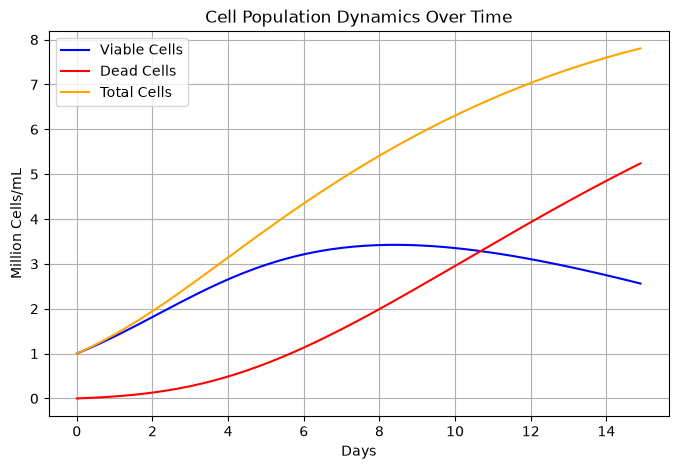

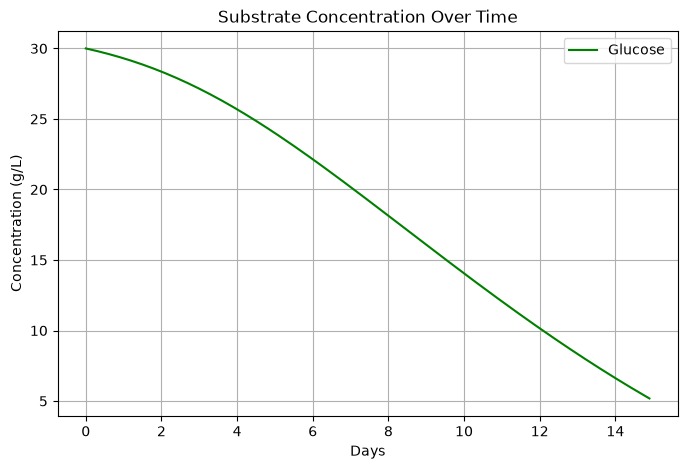

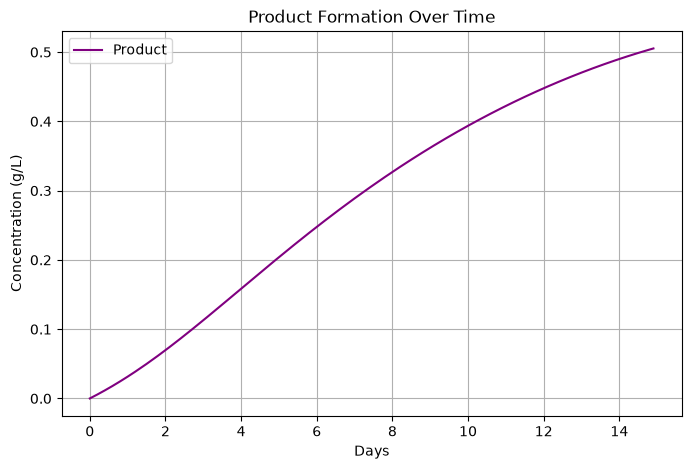

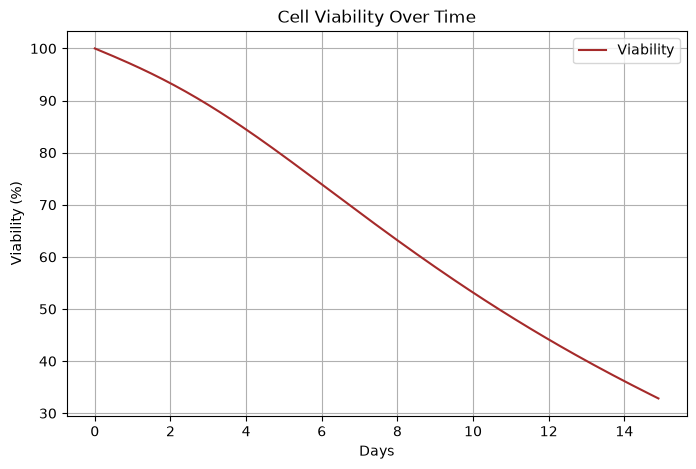

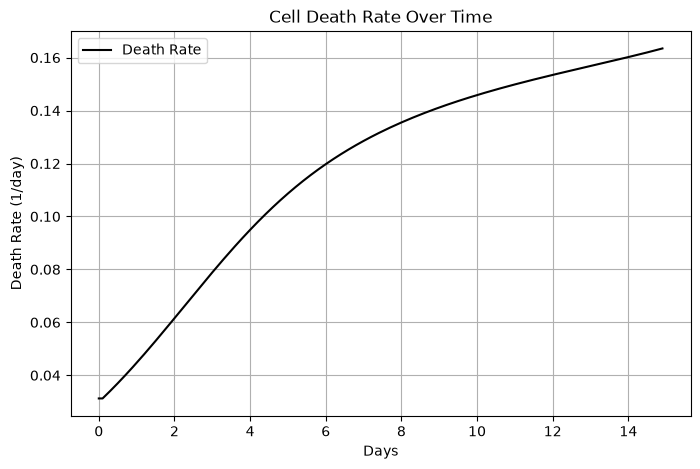

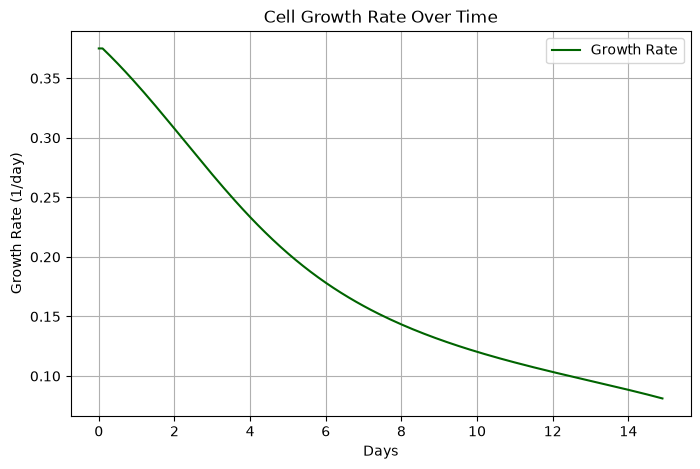

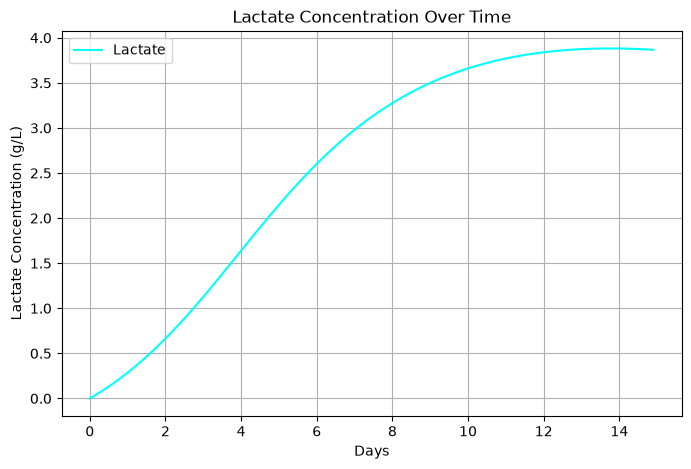

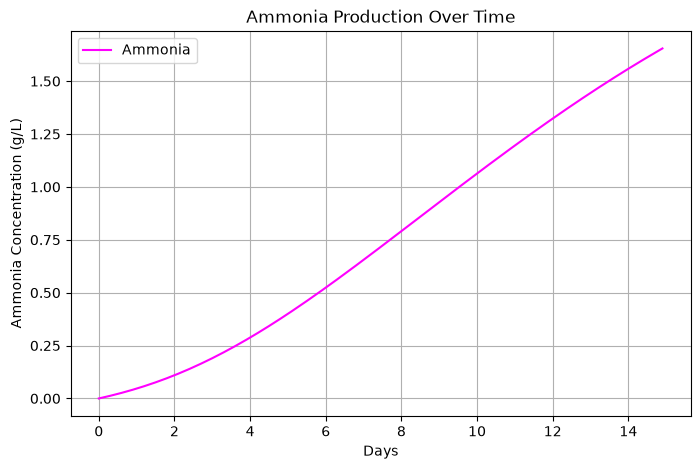

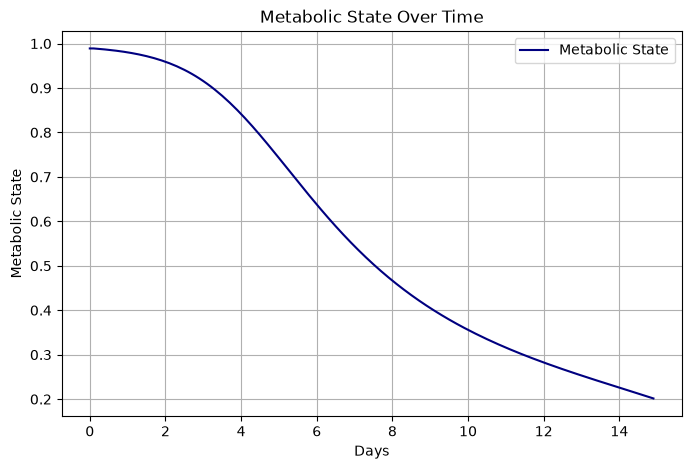

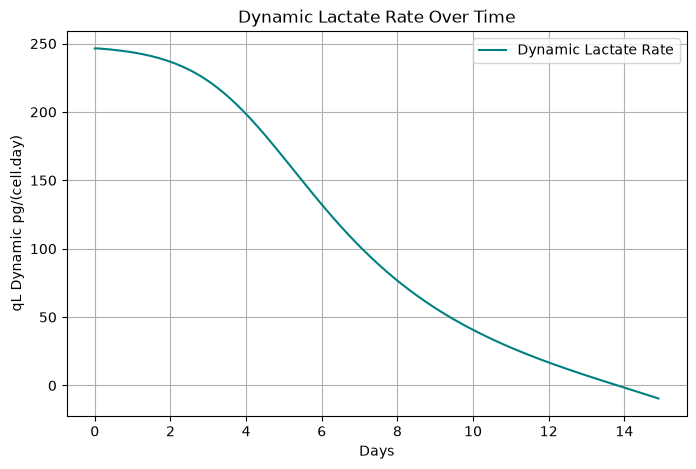

In [11]:
import numpy as np
import matplotlib.pyplot as plt


# =====================================================
# MODEL FUNCTIONS
# =====================================================

def calculate_health(glucose, lactate, ammonia, Ks, Kl, Ka):
    glucose_factor = glucose / (Ks + glucose)
    lactate_factor = Kl / (Kl + lactate)
    ammonia_factor = Ka / (Ka + ammonia)

    health_factor = glucose_factor * lactate_factor * ammonia_factor

    return health_factor


def calculate_death_rate(health_factor, kd_min, kd_max):
    kd = kd_min + (kd_max - kd_min) * (1 - health_factor)

    return kd


def calculate_metabolic_state(mu, mu_switch, switch_steepness):
    metabolic_state = 1 / (
        1 + np.exp(
            -switch_steepness * (mu - mu_switch)
        )
    )

    return metabolic_state


def calculate_growth(viable_cells, mu, dt):
    new_cells = viable_cells * (np.exp(mu * dt) - 1)

    return new_cells


def update_metabolites(
    glucose_previous,
    product_previous,
    lactate_previous,
    ammonia_previous,
    viable_cells_previous,
    qG,
    qp,
    qL_dynamic,
    qA,
    health_factor,
    dt,
):
    cells_per_L = viable_cells_previous * 1e9  # million cells/mL to cells/L
    dynamic_qp = qp * health_factor  # pg/(cell.day)

    glucose_demand = qG * cells_per_L * 1e-12 * dt  # g/L
    actual_glucose_consumed = min(glucose_previous, glucose_demand)  # g/L

    glucose_new = glucose_previous - actual_glucose_consumed  # g/L
    product_new = product_previous + (dynamic_qp * cells_per_L * 1e-12 * dt)  # g/L

    lactate_change = qL_dynamic * cells_per_L * 1e-12 * dt  # g/L
    lactate_new = max(lactate_previous + lactate_change, 0)  # g/L

    ammonia_new = ammonia_previous + (qA * cells_per_L * 1e-12 * dt)  # g/L

    return glucose_new, product_new, lactate_new, ammonia_new


def update_cells(viable_cells_previous, dead_cells_previous, mu, kd, dt):
    new_cells = calculate_growth(viable_cells_previous, mu, dt)  # million cells/mL
    dead_today = kd * viable_cells_previous * dt  # million cells/mL
    dead_today = min(dead_today, viable_cells_previous + new_cells)

    viable_cells_new = viable_cells_previous + new_cells - dead_today  # million cells/mL
    viable_cells_new = max(viable_cells_new, 0)

    dead_cells_new = dead_cells_previous + dead_today  # million cells/mL

    return viable_cells_new, dead_cells_new


# =====================================================
# PLOTTING FUNCTIONS
# =====================================================

def plot_cell_population(days, viable_cells, dead_cells, total_cells):
    plt.figure(figsize=(8, 5))
    plt.plot(days, viable_cells, label="Viable Cells", color="blue")
    plt.plot(days, dead_cells, label="Dead Cells", color="red")
    plt.plot(days, total_cells, label="Total Cells", color="orange")
    plt.title("Cell Population Dynamics Over Time")
    plt.xlabel("Days")
    plt.ylabel("Million Cells/mL")
    plt.legend()
    plt.grid()
    plt.show()


def plot_substrate(days, glucose):
    plt.figure(figsize=(8, 5))
    plt.plot(days, glucose, label="Glucose", color="green")
    plt.title("Substrate Concentration Over Time")
    plt.xlabel("Days")
    plt.ylabel("Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_product(days, product):
    plt.figure(figsize=(8, 5))
    plt.plot(days, product, label="Product", color="purple")
    plt.title("Product Formation Over Time")
    plt.xlabel("Days")
    plt.ylabel("Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_viability(days, viability):
    plt.figure(figsize=(8, 5))
    plt.plot(days, viability, label="Viability", color="brown")
    plt.title("Cell Viability Over Time")
    plt.xlabel("Days")
    plt.ylabel("Viability (%)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_death_rate(days, kd):
    plt.figure(figsize=(8, 5))
    plt.plot(days, kd, label="Death Rate", color="black")
    plt.title("Cell Death Rate Over Time")
    plt.xlabel("Days")
    plt.ylabel("Death Rate (1/day)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_growth_rate(days, mu):
    plt.figure(figsize=(8, 5))
    plt.plot(days, mu, label="Growth Rate", color="darkgreen")
    plt.title("Cell Growth Rate Over Time")
    plt.xlabel("Days")
    plt.ylabel("Growth Rate (1/day)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_lactate(days, lactate):
    plt.figure(figsize=(8, 5))
    plt.plot(days, lactate, label="Lactate", color="cyan")
    plt.title("Lactate Concentration Over Time")
    plt.xlabel("Days")
    plt.ylabel("Lactate Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_ammonia(days, ammonia):
    plt.figure(figsize=(8, 5))
    plt.plot(days, ammonia, label="Ammonia", color="magenta")
    plt.title("Ammonia Production Over Time")
    plt.xlabel("Days")
    plt.ylabel("Ammonia Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_metabolic_state(days, metabolic_state):
    plt.figure(figsize=(8, 5))
    plt.plot(days, metabolic_state, label="Metabolic State", color="navy")
    plt.title("Metabolic State Over Time")
    plt.xlabel("Days")
    plt.ylabel("Metabolic State")
    plt.legend()
    plt.grid()
    plt.show()


def plot_dynamic_lactate_rate(days, dynamic_qL):
    plt.figure(figsize=(8, 5))
    plt.plot(days, dynamic_qL, label="Dynamic Lactate Rate", color="teal")
    plt.title("Dynamic Lactate Rate Over Time")
    plt.xlabel("Days")
    plt.ylabel("qL Dynamic pg/(cell.day)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_results(
    days,
    viable_cells,
    dead_cells,
    total_cells,
    glucose,
    product,
    viability,
    kd,
    mu,
    lactate,
    ammonia,
    metabolic_state,
    dynamic_qL,
):
    plot_cell_population(days, viable_cells, dead_cells, total_cells)
    plot_substrate(days, glucose)
    plot_product(days, product)
    plot_viability(days, viability)
    plot_death_rate(days, kd)
    plot_growth_rate(days, mu)
    plot_lactate(days, lactate)
    plot_ammonia(days, ammonia)
    plot_metabolic_state(days, metabolic_state)
    plot_dynamic_lactate_rate(days, dynamic_qL)


# =====================================================
# MAIN SIMULATION
# =====================================================

def main():

    # ----------------------------
    # Simulation settings
    # ----------------------------

    dt = 0.1  # days
    days = np.arange(0, 15, dt)  # days

    glucose = np.empty(len(days))  # g/L
    product = np.empty(len(days))  # g/L
    viable_cells = np.empty(len(days))  # million cells/mL
    dead_cells = np.empty(len(days))  # million cells/mL
    kd = np.empty(len(days))  # 1/day
    mu = np.empty(len(days))  # 1/day
    lactate = np.empty(len(days))  # g/L
    ammonia = np.empty(len(days))  # g/L
    metabolic_state = np.empty(len(days))  # dimensionless, 0-1
    dynamic_qL = np.empty(len(days))  # pg/(cell.day)

    # ----------------------------
    # Initial Conditions
    # ----------------------------

    glucose[0] = 30.0  # g/L
    initial_cells = 1.0  # million cells/mL
    product[0] = 0.0  # g/L
    viable_cells[0] = initial_cells  # million cells/mL
    dead_cells[0] = 0.0  # million cells/mL
    lactate[0] = 0.0  # g/L
    ammonia[0] = 0.0  # g/L

    # ----------------------------
    # Growth Parameters
    # ----------------------------

    mu_max = 0.4  # 1/day
    Ks = 2.0  # g/L, glucose saturation constant
    Kl = 4.0  # g/L, lactate inhibition constant
    Ka = 2.0  # g/L, ammonia inhibition constant

    # ----------------------------
    # Metabolic Parameters
    # ----------------------------

    qG = 600.0  # pg/(cell.day), glucose consumption rate
    qp = 30.0  # pg/(cell.day), product formation rate
    qA = 40.0  # pg/(cell.day), ammonia production rate

    # Lactate metabolism parameters
    qL_production = 250.0  # pg/(cell.day)
    qL_consumption = 75.0  # pg/(cell.day)

    mu_switch = 0.15  # 1/day
    switch_steepness = 20.0  # dimensionless, controls LP -> LC transition

    # ----------------------------
    # Death Parameters
    # ----------------------------

    kd_min = 0.02  # 1/day, death rate under healthier conditions
    kd_max = 0.20  # 1/day, death rate under stressed conditions

    initial_health = calculate_health(
        glucose[0],
        lactate[0],
        ammonia[0],
        Ks,
        Kl,
        Ka,
    )

    mu[0] = mu_max * initial_health  # 1/day

    kd[0] = calculate_death_rate(
        initial_health,
        kd_min,
        kd_max,
    )

    metabolic_state[0] = calculate_metabolic_state(
        mu[0],
        mu_switch,
        switch_steepness,
    )

    dynamic_qL[0] = (
        metabolic_state[0] * qL_production
        - (1 - metabolic_state[0]) * qL_consumption
    )  # pg/(cell.day)

    # ----------------------------
    # Simulation Loop
    # ----------------------------

    for i in range(1, len(days)):

        health_factor = calculate_health(
            glucose[i-1],
            lactate[i-1],
            ammonia[i-1],
            Ks,
            Kl,
            Ka,
        )

        mu[i] = mu_max * health_factor  # 1/day

        current_metabolic_state = calculate_metabolic_state(
            mu[i],
            mu_switch,
            switch_steepness,
        )

        qL_dynamic = (
            current_metabolic_state * qL_production
            - (1 - current_metabolic_state) * qL_consumption
        )  # pg/(cell.day)

        metabolic_state[i] = current_metabolic_state
        dynamic_qL[i] = qL_dynamic

        kd[i] = calculate_death_rate(
            health_factor,
            kd_min,
            kd_max,
        )

        glucose[i], product[i], lactate[i], ammonia[i] = update_metabolites(
            glucose[i-1],
            product[i-1],
            lactate[i-1],
            ammonia[i-1],
            viable_cells[i-1],
            qG,
            qp,
            qL_dynamic,
            qA,
            health_factor,
            dt,
        )

        viable_cells[i], dead_cells[i] = update_cells(
            viable_cells[i-1],
            dead_cells[i-1],
            mu[i],
            kd[i],
            dt,
        )

    # ----------------------------
    # Derived Variables
    # ----------------------------

    total_cells = viable_cells + dead_cells  # million cells/mL
    viability = viable_cells / total_cells * 100  # %

    # ----------------------------
    # Plot
    # ----------------------------

    plot_results(
        days,
        viable_cells,
        dead_cells,
        total_cells,
        glucose,
        product,
        viability,
        kd,
        mu,
        lactate,
        ammonia,
        metabolic_state,
        dynamic_qL,
    )


# =====================================================
# ENTRY POINT
# =====================================================

if __name__ == "__main__":
    main()

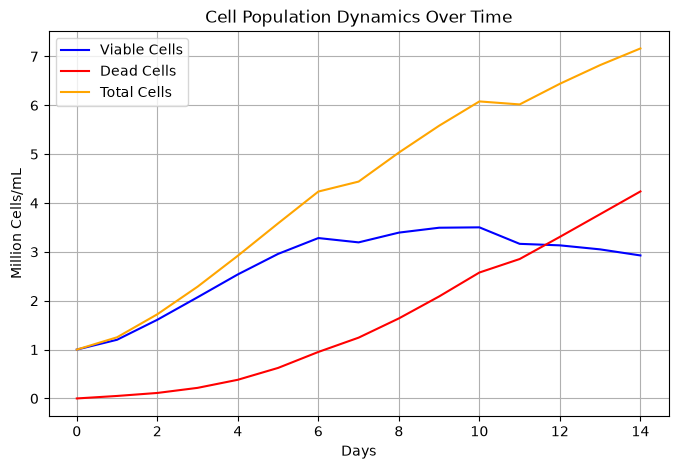

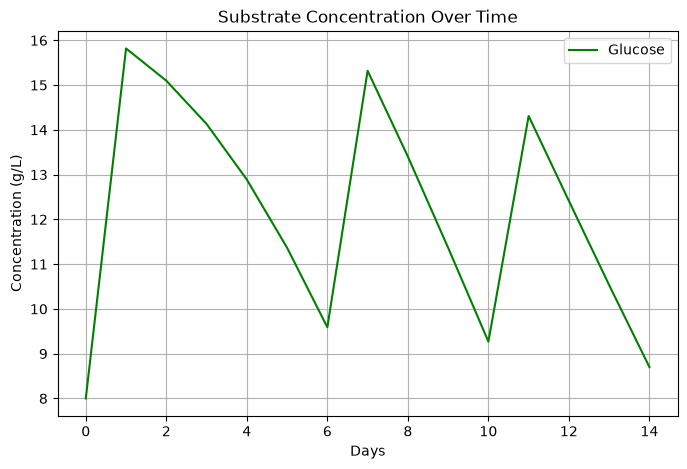

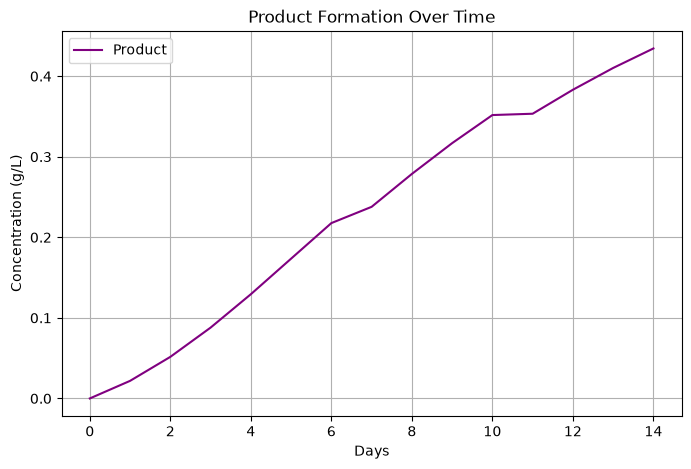

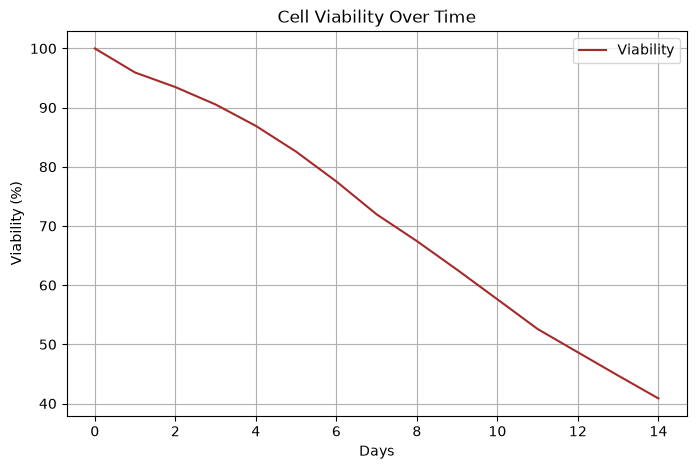

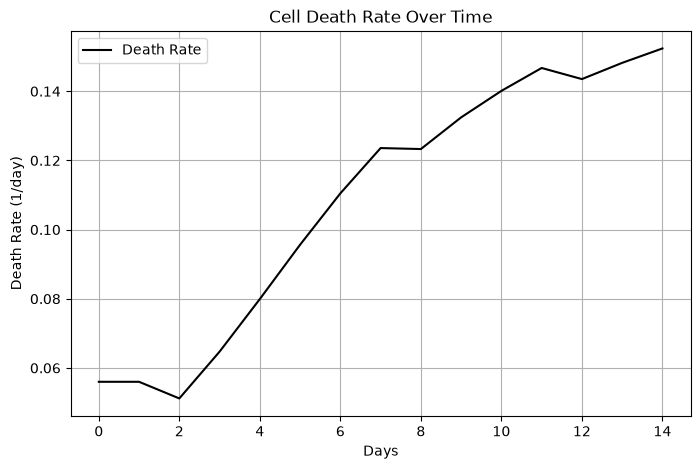

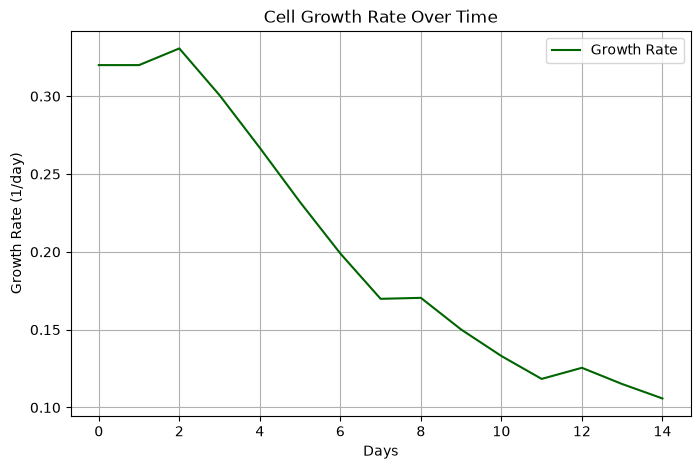

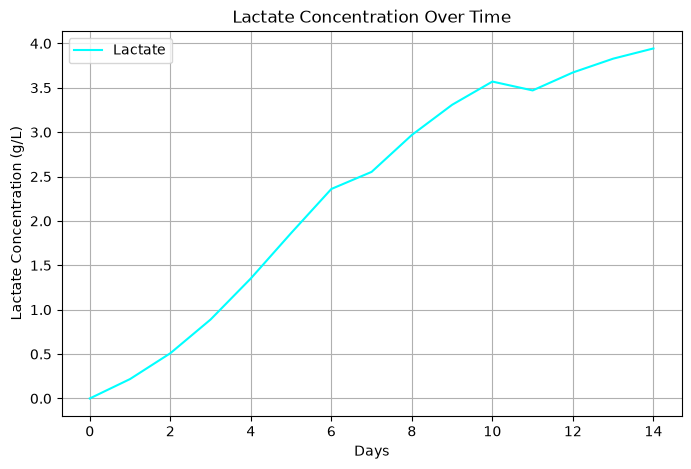

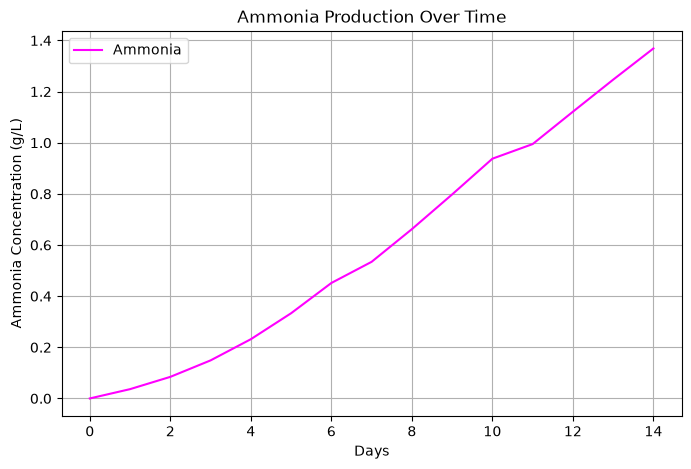

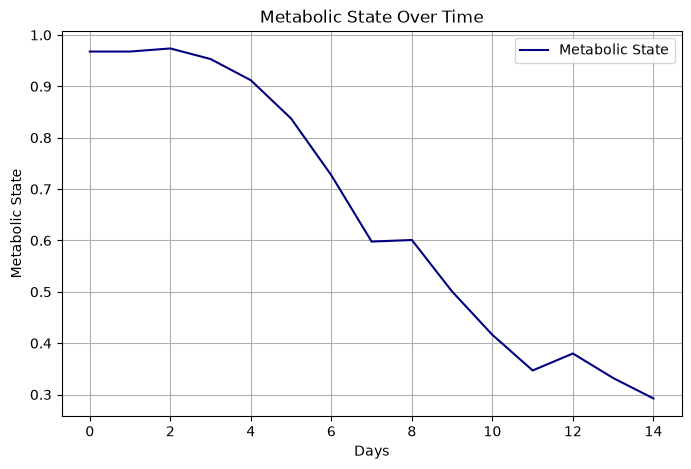

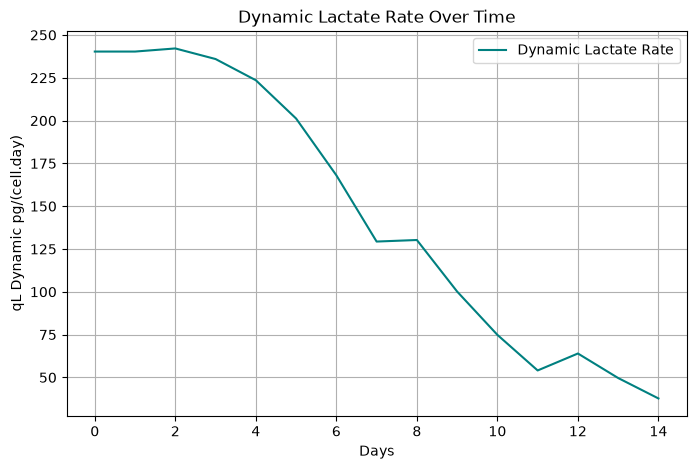

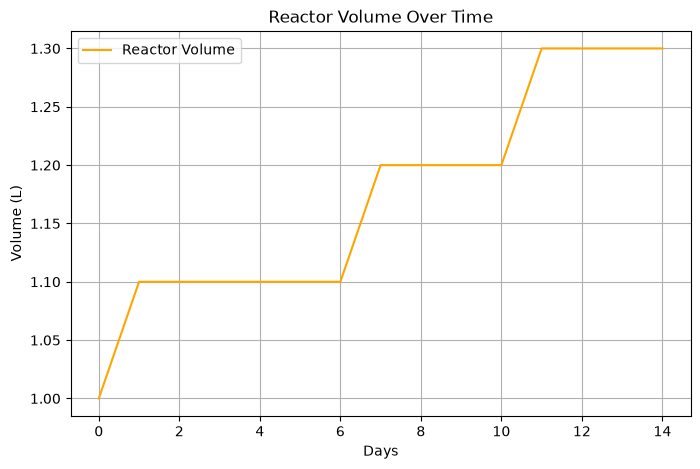

In [8]:
import numpy as np
import matplotlib.pyplot as plt


# =====================================================
# MODEL FUNCTIONS
# =====================================================

def calculate_health(glucose, lactate, ammonia, Ks, Kl, Ka):
    glucose_factor = glucose / (Ks + glucose)
    lactate_factor = Kl / (Kl + lactate)
    ammonia_factor = Ka / (Ka + ammonia)

    health_factor = glucose_factor * lactate_factor * ammonia_factor

    return health_factor


def calculate_death_rate(health_factor, kd_min, kd_max):
    kd = kd_min + (kd_max - kd_min) * (1 - health_factor)

    return kd


def calculate_metabolic_state(mu, mu_switch, switch_steepness):
    metabolic_state = 1 / (
        1 + np.exp(
            -switch_steepness * (mu - mu_switch)
        )
    )

    return metabolic_state


def update_reactor_volume(V_previous, feed_rate, dt):
    V_new = V_previous + feed_rate * dt

    return V_new


def calculate_growth(viable_cells, mu, dt):
    new_cells = viable_cells * (np.exp(mu * dt) - 1)

    return new_cells

def calculate_feed_rate(
        reactor_volume_previous, 
        max_feed_volume, 
        glucose_previous, 
        glucose_target, 
        feed_rate_on, 
        dt,
):
    if reactor_volume_previous >= max_feed_volume or glucose_previous >= glucose_target:
        feed_rate = 0.0

    else:
        feed_rate = feed_rate_on

    feed_rate = min(
        feed_rate, 
        max(((max_feed_volume - reactor_volume_previous) / dt), 0.0))

    return feed_rate

def update_metabolites(
    glucose_previous,
    product_previous,
    lactate_previous,
    ammonia_previous,
    viable_cells_previous,
    reactor_volume_previous,
    reactor_volume_new,
    feed_glucose,
    feed_rate,
    qG,
    qp,
    qL_dynamic,
    qA,
    health_factor,
    dt,
):
    cells_per_L = viable_cells_previous * 1e9  # million cells/mL to cells/L
    dynamic_qp = qp * health_factor  # pg/(cell.day)

    glucose_previous_mass = glucose_previous * reactor_volume_previous  # g
    glucose_added = feed_glucose * feed_rate * dt  # g
    glucose_demand = qG * cells_per_L * reactor_volume_previous * 1e-12 * dt  # g
    actual_glucose_consumed = min(glucose_previous_mass + glucose_added, glucose_demand)  # g

    glucose_new = (
        glucose_previous_mass + glucose_added - actual_glucose_consumed
    ) / reactor_volume_new  # g/L

    product_previous_mass = product_previous * reactor_volume_previous  # g
    product_formed = dynamic_qp * cells_per_L * 1e-12 * dt * reactor_volume_previous  # g
    product_new = (product_previous_mass + product_formed) / reactor_volume_new  # g/L

    lactate_previous_mass = lactate_previous * reactor_volume_previous  # g
    lactate_change = qL_dynamic * cells_per_L * 1e-12 * dt * reactor_volume_previous  # g
    lactate_new = (lactate_previous_mass + lactate_change) / reactor_volume_new  # g/L
    lactate_new = max(lactate_new, 0)  # Prevent negative lactate concentration

    ammonia_previous_mass = ammonia_previous * reactor_volume_previous  # g
    ammonia_formed = qA * cells_per_L * 1e-12 * dt * reactor_volume_previous  # g
    ammonia_new = (ammonia_previous_mass + ammonia_formed) / reactor_volume_new

    return glucose_new, product_new, lactate_new, ammonia_new


def update_cells(viable_cells_previous, reactor_volume_previous, reactor_volume_new, dead_cells_previous, mu, kd, dt):
    viable_cells_previous_mass = viable_cells_previous * 1e9 * reactor_volume_previous  # cells
    new_cells = calculate_growth(viable_cells_previous, mu, dt)  # million cells/mL
    new_cells_mass = new_cells * 1e9 * reactor_volume_previous  # cells

    dead_today = kd * viable_cells_previous * dt  # million cells/mL
    dead_today = min(dead_today, viable_cells_previous + new_cells)
    dead_today_mass = dead_today * 1e9 * reactor_volume_previous  # cells

    viable_cells_new = (((viable_cells_previous_mass + new_cells_mass - dead_today_mass)/
                        reactor_volume_new/
                        1e9)
    )  # million cells/mL
    viable_cells_new = max(viable_cells_new, 0)

    dead_cells_new = (((dead_cells_previous * 1e9 * reactor_volume_previous) + dead_today_mass) / 
                      reactor_volume_new / 
                      1e9
    )  # million cells/mL

    return viable_cells_new, dead_cells_new


# =====================================================
# PLOTTING FUNCTIONS
# =====================================================

def plot_cell_population(days, viable_cells, dead_cells, total_cells):
    plt.figure(figsize=(8, 5))
    plt.plot(days, viable_cells, label="Viable Cells", color="blue")
    plt.plot(days, dead_cells, label="Dead Cells", color="red")
    plt.plot(days, total_cells, label="Total Cells", color="orange")
    plt.title("Cell Population Dynamics Over Time")
    plt.xlabel("Days")
    plt.ylabel("Million Cells/mL")
    plt.legend()
    plt.grid()
    plt.show()


def plot_substrate(days, glucose):
    plt.figure(figsize=(8, 5))
    plt.plot(days, glucose, label="Glucose", color="green")
    plt.title("Substrate Concentration Over Time")
    plt.xlabel("Days")
    plt.ylabel("Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_product(days, product):
    plt.figure(figsize=(8, 5))
    plt.plot(days, product, label="Product", color="purple")
    plt.title("Product Formation Over Time")
    plt.xlabel("Days")
    plt.ylabel("Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_viability(days, viability):
    plt.figure(figsize=(8, 5))
    plt.plot(days, viability, label="Viability", color="brown")
    plt.title("Cell Viability Over Time")
    plt.xlabel("Days")
    plt.ylabel("Viability (%)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_death_rate(days, kd):
    plt.figure(figsize=(8, 5))
    plt.plot(days, kd, label="Death Rate", color="black")
    plt.title("Cell Death Rate Over Time")
    plt.xlabel("Days")
    plt.ylabel("Death Rate (1/day)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_growth_rate(days, mu):
    plt.figure(figsize=(8, 5))
    plt.plot(days, mu, label="Growth Rate", color="darkgreen")
    plt.title("Cell Growth Rate Over Time")
    plt.xlabel("Days")
    plt.ylabel("Growth Rate (1/day)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_lactate(days, lactate):
    plt.figure(figsize=(8, 5))
    plt.plot(days, lactate, label="Lactate", color="cyan")
    plt.title("Lactate Concentration Over Time")
    plt.xlabel("Days")
    plt.ylabel("Lactate Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_ammonia(days, ammonia):
    plt.figure(figsize=(8, 5))
    plt.plot(days, ammonia, label="Ammonia", color="magenta")
    plt.title("Ammonia Production Over Time")
    plt.xlabel("Days")
    plt.ylabel("Ammonia Concentration (g/L)")
    plt.legend()
    plt.grid()
    plt.show()


def plot_metabolic_state(days, metabolic_state):
    plt.figure(figsize=(8, 5))
    plt.plot(days, metabolic_state, label="Metabolic State", color="navy")
    plt.title("Metabolic State Over Time")
    plt.xlabel("Days")
    plt.ylabel("Metabolic State")
    plt.legend()
    plt.grid()
    plt.show()


def plot_dynamic_lactate_rate(days, dynamic_qL):
    plt.figure(figsize=(8, 5))
    plt.plot(days, dynamic_qL, label="Dynamic Lactate Rate", color="teal")
    plt.title("Dynamic Lactate Rate Over Time")
    plt.xlabel("Days")
    plt.ylabel("qL Dynamic pg/(cell.day)")
    plt.legend()
    plt.grid()
    plt.show()

def plot_reactor_volume(days, reactor_volume):
    plt.figure(figsize=(8, 5))
    plt.plot(days, reactor_volume, label="Reactor Volume", color="orange")
    plt.title("Reactor Volume Over Time")
    plt.xlabel("Days")
    plt.ylabel("Volume (L)")
    plt.legend()
    plt.grid()
    plt.show()

def plot_results(
    days,
    viable_cells,
    dead_cells,
    total_cells,
    glucose,
    product,
    viability,
    kd,
    mu,
    lactate,
    ammonia,
    metabolic_state,
    dynamic_qL, 
    reactor_volume
):
    plot_cell_population(days, viable_cells, dead_cells, total_cells)
    plot_substrate(days, glucose)
    plot_product(days, product)
    plot_viability(days, viability)
    plot_death_rate(days, kd)
    plot_growth_rate(days, mu)
    plot_lactate(days, lactate)
    plot_ammonia(days, ammonia)
    plot_metabolic_state(days, metabolic_state)
    plot_dynamic_lactate_rate(days, dynamic_qL)
    plot_reactor_volume(days, reactor_volume)

# =====================================================
# MAIN SIMULATION
# =====================================================

def main():

    # ----------------------------
    # Simulation settings
    # ----------------------------

    days = np.arange(0, 15)  # days

    reactor_volume = np.empty(len(days))  # L
    feed_rate = np.zeros(len(days))  # L/day
    glucose = np.empty(len(days))  # g/L
    product = np.empty(len(days))  # g/L
    viable_cells = np.empty(len(days))  # million cells/mL
    dead_cells = np.empty(len(days))  # million cells/mL
    kd = np.empty(len(days))  # 1/day
    mu = np.empty(len(days))  # 1/day
    lactate = np.empty(len(days))  # g/L
    ammonia = np.empty(len(days))  # g/L
    metabolic_state = np.empty(len(days))  # dimensionless, 0-1
    dynamic_qL = np.empty(len(days))  # pg/(cell.day)

    # ----------------------------
    # Initial Conditions
    # ----------------------------

    reactor_volume[0] = 1.0  # L
    glucose[0] = 8.0  # g/L
    initial_cells = 1.0  # million cells/mL
    product[0] = 0.0  # g/L
    viable_cells[0] = initial_cells  # million cells/mL
    dead_cells[0] = 0.0  # million cells/mL
    lactate[0] = 0.0  # g/L
    ammonia[0] = 0.0  # g/L

    # ----------------------------
    # Feed Parameters
    # ----------------------------

    feed_glucose = 100.0  # g/L, glucose concentration in feed
    feed_rate_on = 0.1  # L/day
    glucose_target = 10.0  # g/L, target glucose concentration
    max_feed_volume = 1.5  # L, maximum reactor volume for feeding
    # reactor_capacity = 2.0  # L, maximum reactor volume

    # ----------------------------
    # Growth Parameters
    # ----------------------------

    mu_max = 0.4  # 1/day
    Ks = 2.0  # g/L, glucose saturation constant
    Kl = 4.0  # g/L, lactate inhibition constant
    Ka = 2.0  # g/L, ammonia inhibition constant

    # ----------------------------
    # Metabolic Parameters
    # ----------------------------

    qG = 600.0  # pg/(cell.day), glucose consumption rate
    qp = 30.0  # pg/(cell.day), product formation rate
    qA = 40.0  # pg/(cell.day), ammonia production rate

    # Lactate metabolism parameters
    qL_production = 250.0  # pg/(cell.day)
    qL_consumption = 50.0  # pg/(cell.day)

    mu_switch = 0.15  # 1/day
    switch_steepness = 20.0  # dimensionless, controls LP -> LC transition

    dt = 1.0  # days

    # ----------------------------
    # Death Parameters
    # ----------------------------

    kd_min = 0.02  # 1/day, death rate under healthier conditions
    kd_max = 0.20  # 1/day, death rate under stressed conditions

    initial_health = calculate_health(
        glucose[0],
        lactate[0],
        ammonia[0],
        Ks,
        Kl,
        Ka,
    )

    mu[0] = mu_max * initial_health  # 1/day

    kd[0] = calculate_death_rate(
        initial_health,
        kd_min,
        kd_max,
    )

    metabolic_state[0] = calculate_metabolic_state(
        mu[0],
        mu_switch,
        switch_steepness,
    )

    dynamic_qL[0] = (
        metabolic_state[0] * qL_production
        - (1 - metabolic_state[0]) * qL_consumption
    )  # pg/(cell.day)

    # ----------------------------
    # Simulation Loop
    # ----------------------------

    for i in range(1, len(days)):

        feed_rate[i-1] = calculate_feed_rate(
            reactor_volume[i-1],
            max_feed_volume,
            glucose[i-1],
            glucose_target,
            feed_rate_on,
            dt,
        )

        health_factor = calculate_health(
            glucose[i-1],
            lactate[i-1],
            ammonia[i-1],
            Ks,
            Kl,
            Ka,
        )

        mu[i] = mu_max * health_factor  # 1/day

        current_metabolic_state = calculate_metabolic_state(
            mu[i],
            mu_switch,
            switch_steepness,
        )

        qL_dynamic = (
            current_metabolic_state * qL_production
            - (1 - current_metabolic_state) * qL_consumption
        )  # pg/(cell.day)

        metabolic_state[i] = current_metabolic_state
        dynamic_qL[i] = qL_dynamic

        kd[i] = calculate_death_rate(
            health_factor,
            kd_min,
            kd_max,
        )

        reactor_volume[i] = update_reactor_volume(
            reactor_volume[i-1],
            feed_rate[i-1],
            dt,
        )

        glucose[i], product[i], lactate[i], ammonia[i] = update_metabolites(
            glucose[i-1],
            product[i-1],
            lactate[i-1],
            ammonia[i-1],
            viable_cells[i-1],
            reactor_volume[i-1],
            reactor_volume[i],
            feed_glucose,
            feed_rate[i-1],
            qG,
            qp,
            qL_dynamic,
            qA,
            health_factor,
            dt,
        )

        viable_cells[i], dead_cells[i] = update_cells(
            viable_cells[i-1],
            reactor_volume[i-1],
            reactor_volume[i],
            dead_cells[i-1],
            mu[i],
            kd[i],
            dt,
        )

    # ----------------------------
    # Derived Variables
    # ----------------------------

    total_cells = viable_cells + dead_cells  # million cells/mL
    viability = viable_cells / total_cells * 100  # %

    # ----------------------------
    # Plot
    # ----------------------------

    plot_results(
        days,
        viable_cells,
        dead_cells,
        total_cells,
        glucose,
        product,
        viability,
        kd,
        mu,
        lactate,
        ammonia,
        metabolic_state,
        dynamic_qL, 
        reactor_volume
    )


# =====================================================
# ENTRY POINT
# =====================================================

if __name__ == "__main__":
    main()
